In [1]:
import scanpy as sc 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Environment ready")

Environment ready


In [2]:
adata = sc.datasets.pbmc3k()
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [3]:
# look at the cell info
adata.obs.head()

""
index
AAACATACAACCAC-1
AAACATTGAGCTAC-1
AAACATTGATCAGC-1
AAACCGTGCTTCCG-1
AAACCGTGTATGCG-1


In [4]:
# look at the gene info 
adata.var.head()

,gene_ids
index,
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945


In [5]:
adata



AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [6]:
type(adata)

anndata.AnnData

In [7]:
adata.X[:5,:5].toarray()

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]], dtype=float32)

In [8]:
sc.pp.calculate_qc_metrics(adata, inplace=True)

In [9]:
adata.obs.head()

,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
index,,,,,,,,
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,47.748864,63.279637,74.969021,88.393226
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,45.502753,61.023863,71.813176,82.622884
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,41.314703,53.794856,65.449349,79.961893
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,39.029936,52.898825,66.691929,82.569155
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,44.852192,55.657492,67.176351,97.757390


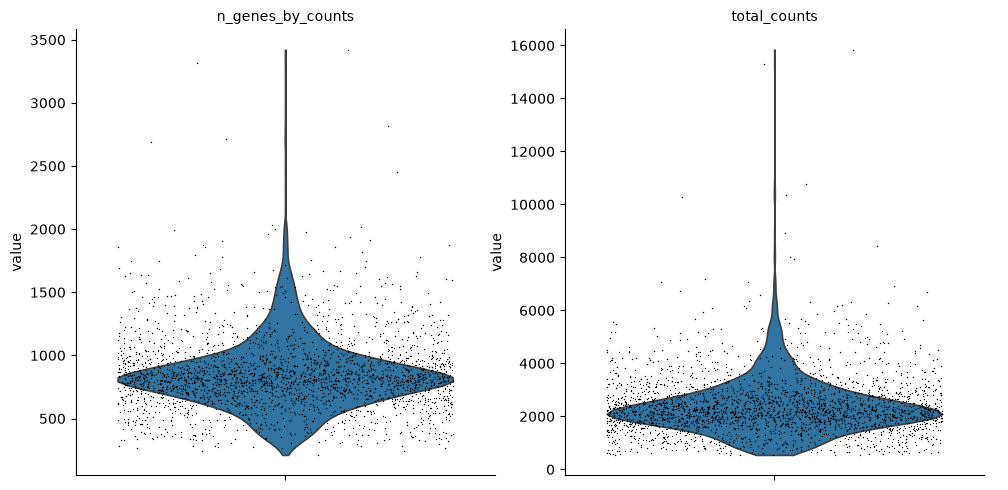

In [10]:
# plotting the number of genes detected in each cell shows us that most cells express about 900 genes and few express a lot more 
# it also shows us that most cells have about 2000 transcripts and few have more than that
# this plots the data from 2 cols in adata.obs
sc.pl.violin(
    adata, 
    ["n_genes_by_counts", "total_counts"], 
    jitter=0.4, 
    multi_panel=True
)

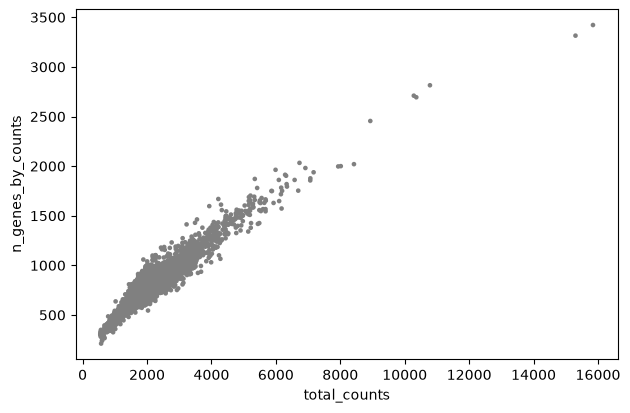

In [11]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts"
)
# the more rna molecules there are the more genes they express, but they're clustered in a certain range

In [12]:
# since obs is a pd df, you use 2 brackets to select 2 cols 
# describe takes those 2 cols and tells you metrics for all cells
# count tells you the number of cells, mean tells how many genes on average each cell expresses, and how many rnas seen in each cell on average 

adata.obs[["n_genes_by_counts", "total_counts"]].describe()


,n_genes_by_counts,total_counts
count,2700.000000,2700.000000
mean,846.994074,2366.900391
std,282.104964,1094.262085
min,212.000000,548.000000
25%,690.000000,1757.750000
50%,817.000000,2197.000000
75%,953.250000,2763.000000
max,3422.000000,15844.000000


In [13]:
# creates a new col in var called mt that takes all the mt genes and their data
adata.var["mt"] = adata.var_names.str.startswith("MT")

# calculates qc metrics on the mt genes 
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],  
    inplace=True
)

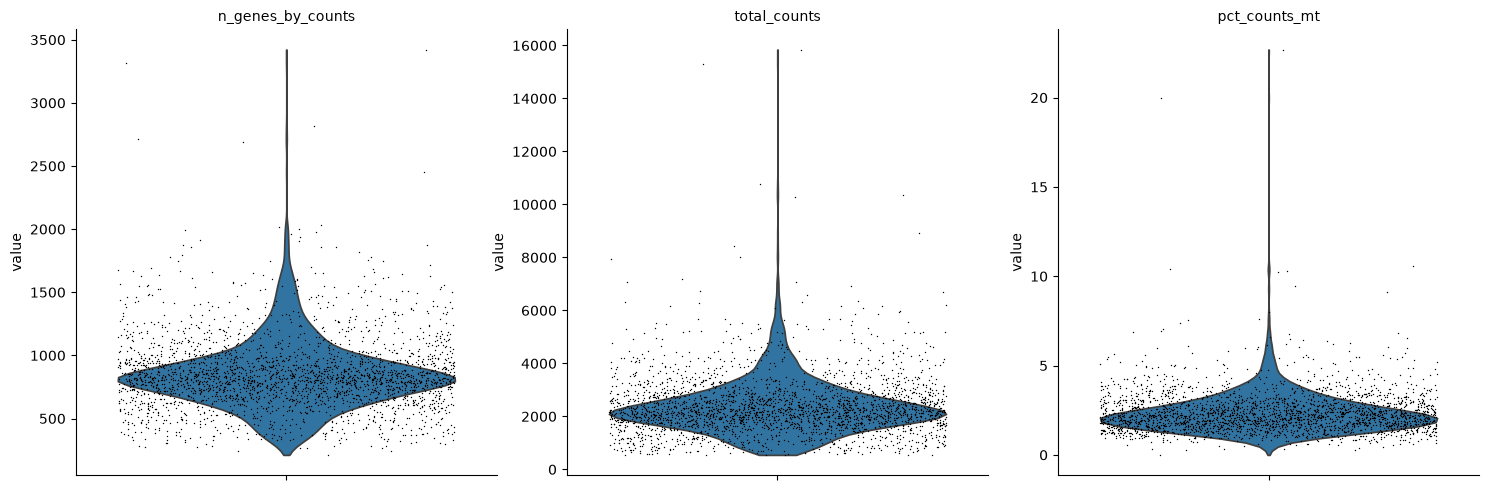

In [14]:
# scanpy searches for the df .obs only for .violin
sc.pl.violin(
    adata, 
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"], 
    jitter=0.4, 
    multi_panel=True
)
# i notice that most cells have 900 genes in them
# most cells have 2000 rna molecules in them 
# most cells have 3% mt genes making up all genes 

In [15]:
# gives stats for pct counts of mt rna across all cells 
adata.obs["pct_counts_mt"].describe()
# avg 2.3% mtrna, std is 1.1, some have no mtrna, 75% is 2.7 and the max is really high at 22 

count    2700.000000
mean        2.356714
std         1.175540
min         0.000000
25%         1.655864
50%         2.168459
75%         2.797307
max        22.689075
Name: pct_counts_mt, dtype: float64

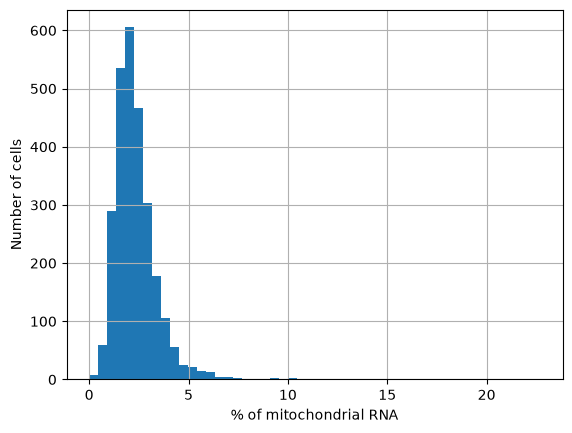

In [16]:
adata.obs["pct_counts_mt"].hist(bins=50)
plt.xlabel("% of mitochondrial RNA")
plt.ylabel("Number of cells")
plt.show()

In [17]:
# save original count of cells 
n_before = adata.n_obs

# adjust what we care to see in adata
# keep cells that express at least 300 and no more than 2500 different genes and 
adata = adata[adata.obs.n_genes_by_counts > 300, :]
adata = adata[adata.obs.n_genes_by_counts < 2500, :]

# also dropping cells that have too much rna (indicates low quality)
adata = adata[adata.obs.pct_counts_mt < 5, :]

# count after filtering
n_after = adata.n_obs

print(f"{n_before} cells before, {n_after} cells after")

2700 cells before, 2616 cells after


In [18]:
sc.pp.normalize_total(adata, target_sum=10000)
# target sum means the expression data is normalized so that if you add up all counts of rna molecules for each cell they'd be approx 10000

adata.obs["total_counts"].head()
# normalizing the data doesn't change total counts because its exists in the obs df not the X df

/var/folders/gv/gbf3xv4d3hl0xccvbw6j48_m0000gn/T/ipykernel_4262/2227822548.py:1: UserWarning: Received a view of an AnnData. Making a copy.
  sc.pp.normalize_total(adata, target_sum=10000)


index
AAACATACAACCAC-1    2421.0
AAACATTGAGCTAC-1    4903.0
AAACATTGATCAGC-1    3149.0
AAACCGTGCTTCCG-1    2639.0
AAACCGTGTATGCG-1     981.0
Name: total_counts, dtype: float32

In [19]:
# lets see the X df to see the normalization
adata.X.sum(axis=1)
# adding up expression values across cols totals to 10000 bc each cell expresses approx 10000 molecules

matrix([[10000.   ],
        [10000.   ],
        [10000.   ],
        ...,
        [10000.001],
        [10000.   ],
        [10000.   ]], shape=(2616, 1), dtype=float32)

In [20]:
# make it a np arr and flatten it to a vector and show first 10
# all values are close to 10000 bc each cell expresses about the same rna 
np.array(adata.X.sum(axis=1)).flatten()[:10]

array([10000.   , 10000.   , 10000.   ,  9999.998,  9999.999, 10000.   ,
        9999.999, 10000.   , 10000.001, 10000.   ], dtype=float32)

In [21]:
# log transform adata to adjust large skewed values
# this makes large values smaller and small values bigger 
sc.pp.log1p(adata)

In [22]:
bef = adata.n_vars
sc.pp.highly_variable_genes(adata)
print(bef, adata.n_vars)
# adds new col called highly_variable which tells you if the gene varies across cell types or not
adata.var.head()


32738 32738


,gene_ids,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,mt,highly_variable,means,dispersions,dispersions_norm
index,,,,,,,,,,,,
MIR1302-10,ENSG00000243485,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
FAM138A,ENSG00000237613,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
OR4F5,ENSG00000186092,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
RP11-34P13.7,ENSG00000238009,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
RP11-34P13.8,ENSG00000239945,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN


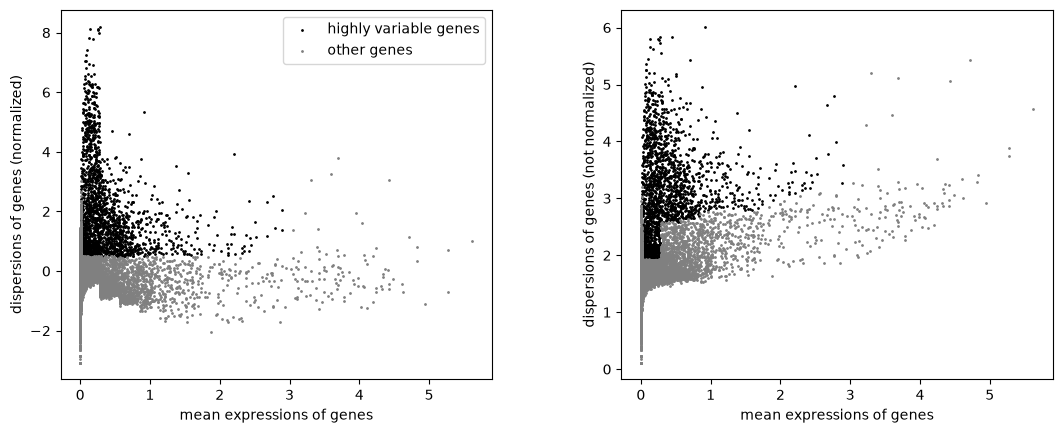

In [23]:
sc.pl.highly_variable_genes(adata)
# most genes are highly variable, many express around same range 
# y axis, the higher, the more variable the expression between T and B cells are, 
# the genes near the top might be best?
# the genes to the right are expressed most but we care more about how variable the genes are


In [24]:
# filter with just the highly variable genes
adata = adata[:, adata.var["highly_variable"]]
print(f"only {adata.n_vars} genes remain, there were {bef} before")


only 1987 genes remain, there were 32738 before


In [25]:
# we have 1987 features now, which is way less than 32k but we can still reduce it using pca
# pca will help us find pcs that capture the important insights 
sc.tl.pca(adata)
# view the np arr called X_pca stored in obsm, which is a container like a dict using [] for access
adata.obsm["X_pca"].shape
# there are 50 pcs and 2616 cells 


/Users/yukamurakami/miniconda3/envs/scRNA/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:357: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


(2616, 50)

In [26]:
# lets look at first 5 pcs
adata.obsm["X_pca"][:, 5]
# with these 50 pcs we have a cleaner feature space 

array([-1.2348557 ,  0.21610755,  1.0278535 , ...,  0.21296255,
        0.22195226, -0.8269914 ], shape=(2616,), dtype=float32)

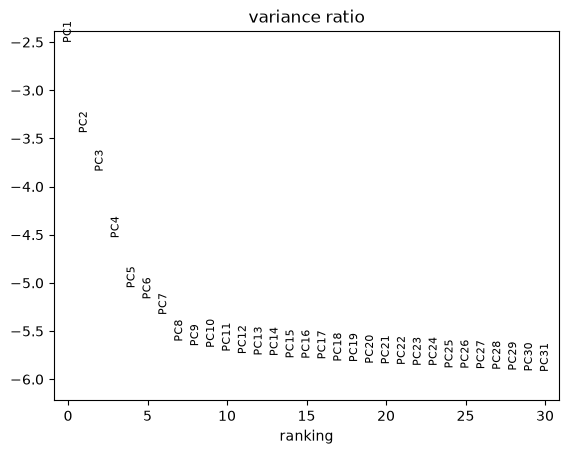

In [27]:
# lets use scree plot to visualize the pcs 
sc.pl.pca_variance_ratio(adata, log=True)

In [28]:
# cells that have similar expression should be near each other in a graph 
# we're going with 10 pcs to use some of the info the later pcs give too
# n_neighbors means find the 10 most similar cells for each cell, not all cells are shown
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10) 
adata.obsp.keys() # obsp means observation pair, how pairs of cells relate to each other 


KeysView(PairwiseArrays with keys: 'distances', 'connectivities')

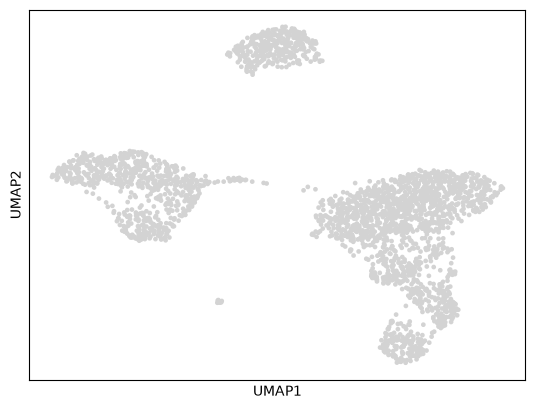

In [29]:
# UMAP 
sc.tl.umap(adata)
sc.pl.umap(adata)

In [30]:
sc.tl.leiden(adata)
adata.obs.head()

/var/folders/gv/gbf3xv4d3hl0xccvbw6j48_m0000gn/T/ipykernel_4262/2658440798.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)


,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,leiden
index,,,,,,,,,,,,
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,47.748864,63.279637,74.969021,88.393226,75.0,4.330733,3.097893,5
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,45.502753,61.023863,71.813176,82.622884,190.0,5.252274,3.875179,0
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,41.314703,53.794856,65.449349,79.961893,34.0,3.555348,1.079708,7
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,39.029936,52.898825,66.691929,82.569155,52.0,3.970292,1.970443,3
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,44.852192,55.657492,67.176351,97.757390,14.0,2.708050,1.427115,8


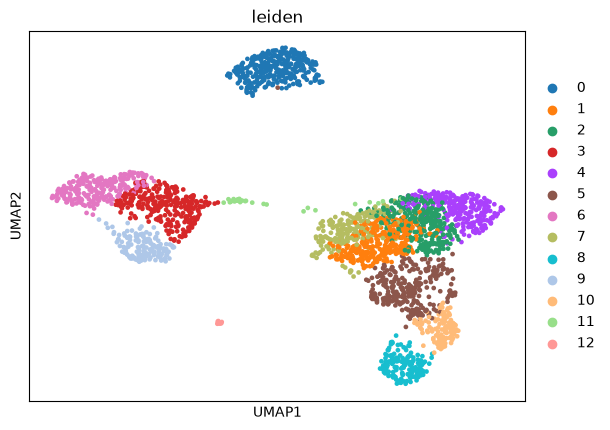

In [31]:
sc.pl.umap(
    adata, 
    color="leiden"
)

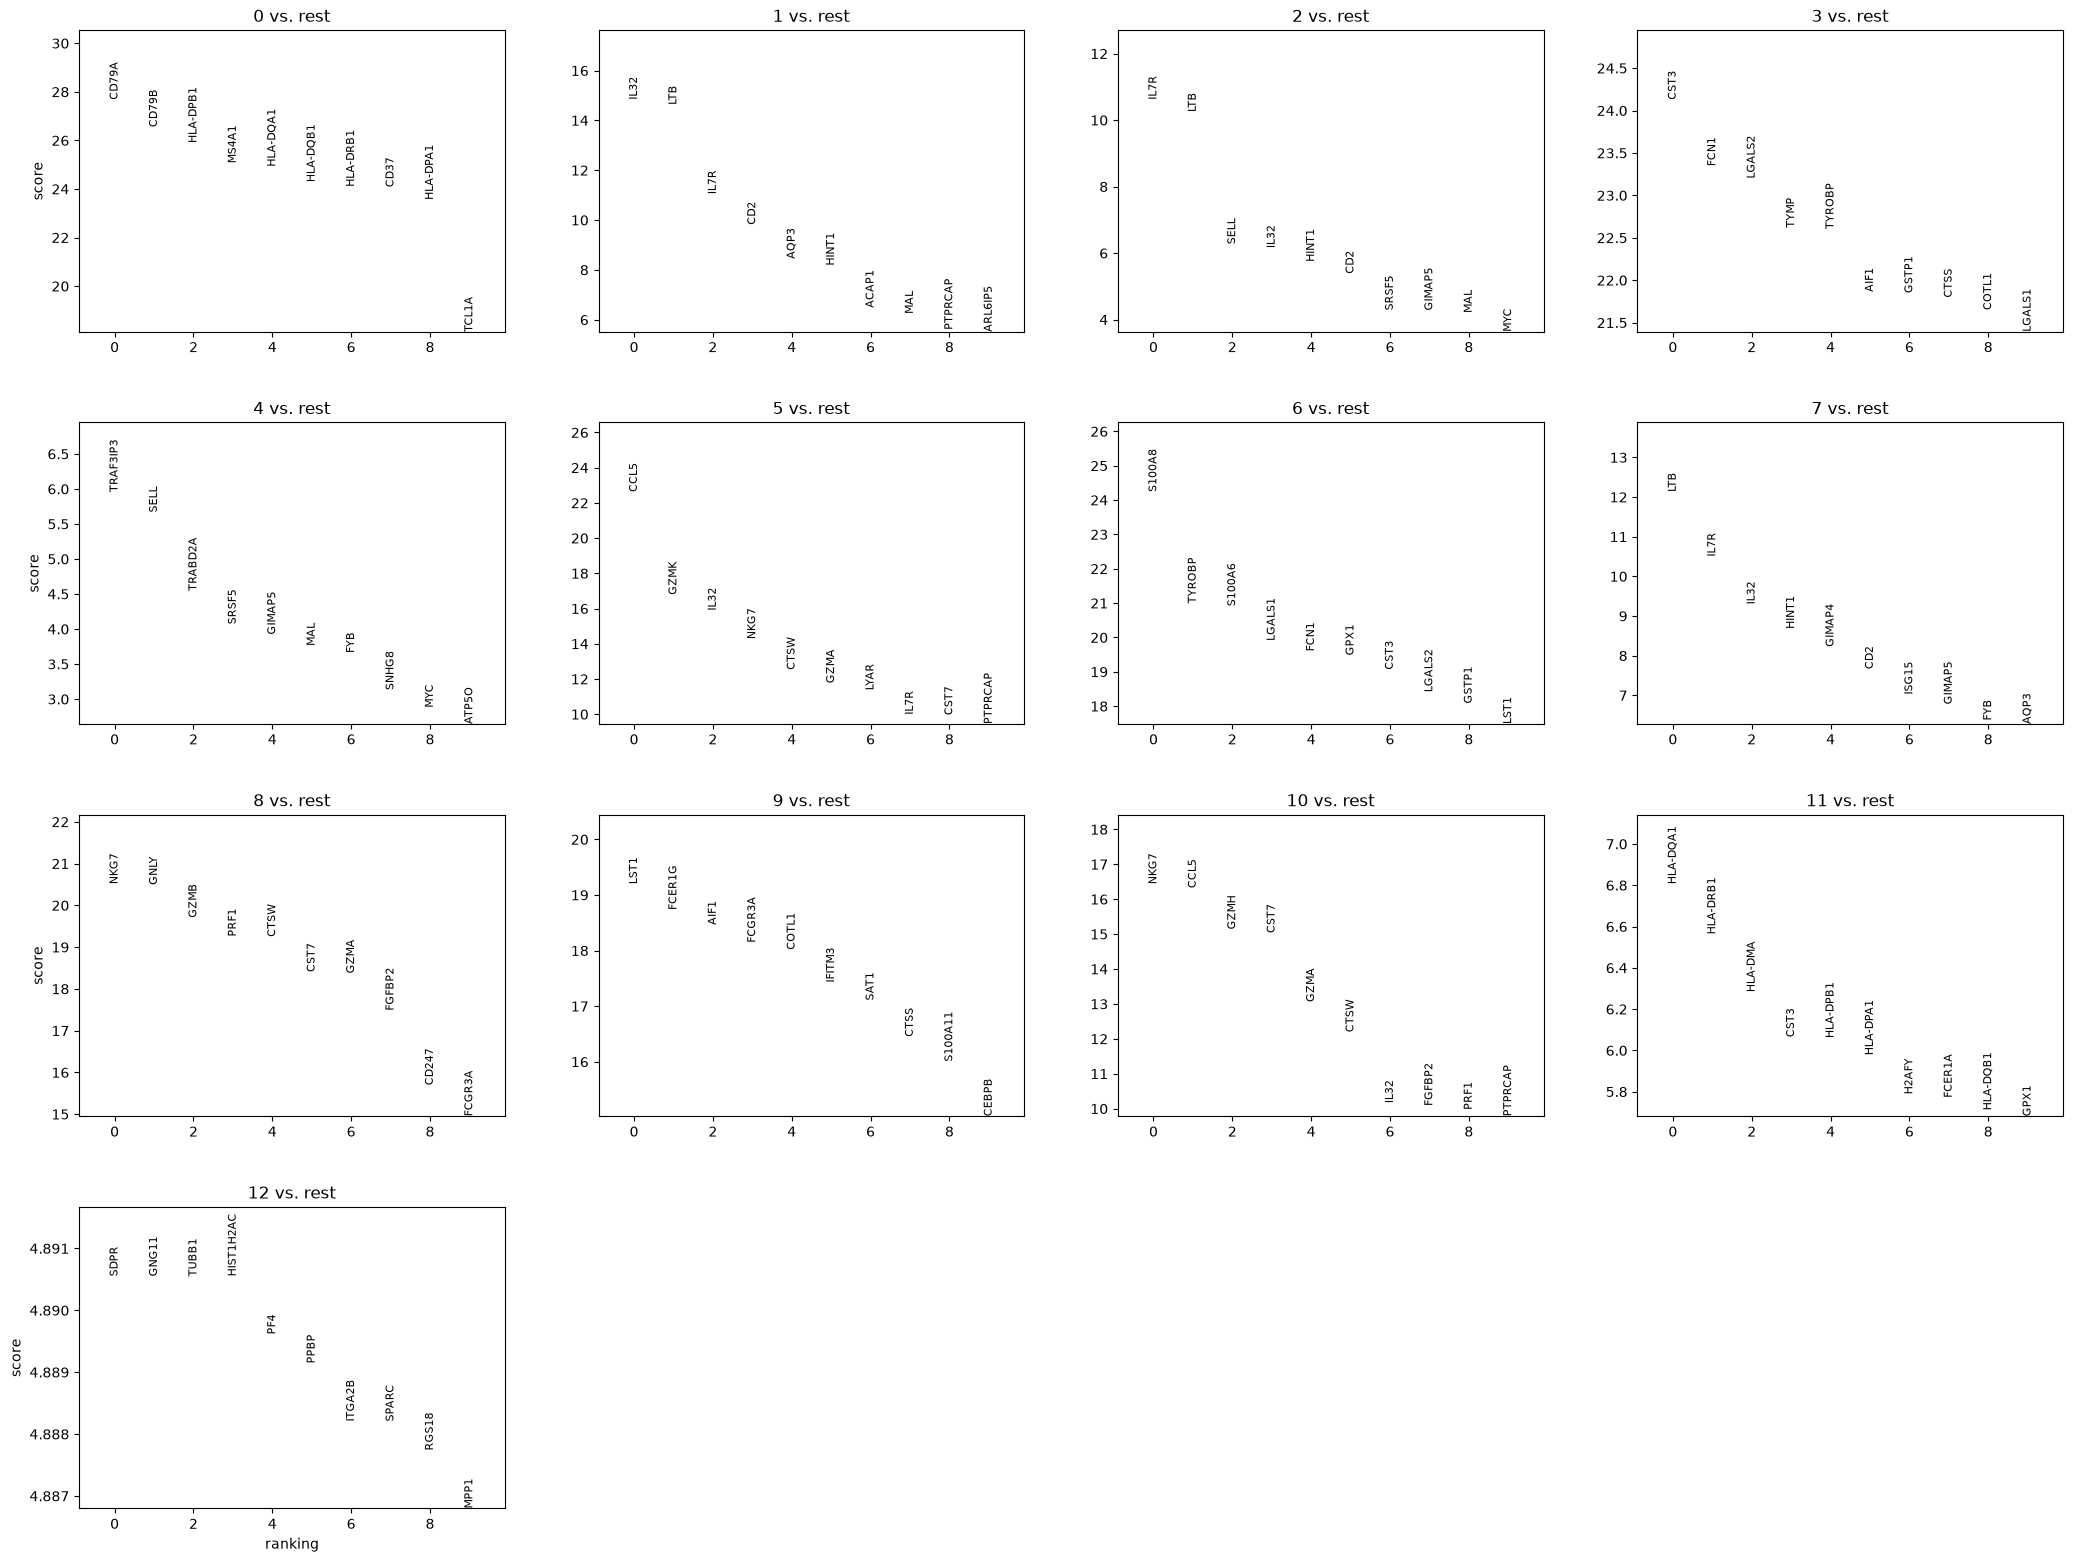

In [32]:
# this will tell us for each cluster which gene is highest expressed
sc.tl.rank_genes_groups(
    adata, 
    groupby="leiden", 
    method="wilcoxon"
)
sc.pl.rank_genes_groups(
    adata, 
    n_genes=10, 
    sharey=False
)

In [33]:
result = sc.get.rank_genes_groups_df(
    adata, 
    group=None
)
result.head()

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
2,0,HLA-DPB1,25.892418,4.072172,8.106834e-148,5.369426e-145
3,0,MS4A1,25.057699,6.423985,1.439133e-138,7.148895e-136
4,0,HLA-DQA1,24.917364,5.313763,4.824401e-137,1.917217e-134


In [34]:
top5 = (
    result
    .sort_values(["group", "scores"], ascending=[True, False]) # sort group in ascending order and scores in descending
    .groupby("group") # groups each cluster
    .head(5) # shows top 5 genes for each cluster
)
top5

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
2,0,HLA-DPB1,25.892418,4.072172,8.106834e-148,5.369426e-145
3,0,MS4A1,25.057699,6.423985,1.439133e-138,7.148895e-136
4,0,HLA-DQA1,24.917364,5.313763,4.824401e-137,1.917217e-134
...,...,...,...,...,...,...
23844,12,SDPR,4.890548,12.220600,1.005555e-06,1.540032e-04
23845,12,GNG11,4.890548,12.436696,1.005555e-06,1.540032e-04
23846,12,TUBB1,4.890548,11.289756,1.005555e-06,1.540032e-04
23847,12,HIST1H2AC,4.890548,10.322406,1.005555e-06,1.540032e-04


In [35]:
top5[["group", "names"]] # pulls a subset of the df with cols group and names

,group,names
0,0,CD79A
1,0,CD79B
2,0,HLA-DPB1
3,0,MS4A1
4,0,HLA-DQA1
...,...,...
23844,12,SDPR
23845,12,GNG11
23846,12,TUBB1
23847,12,HIST1H2AC


In [36]:
characteristic_genes = {}
for i in range(13):
    genes = top5[top5["group"] == str(i)]["names"].tolist()
    characteristic_genes[i] = genes

print(characteristic_genes)

{0: ['CD79A', 'CD79B', 'HLA-DPB1', 'MS4A1', 'HLA-DQA1'], 1: ['IL32', 'LTB', 'IL7R', 'CD2', 'AQP3'], 2: ['IL7R', 'LTB', 'SELL', 'IL32', 'HINT1'], 3: ['CST3', 'FCN1', 'LGALS2', 'TYMP', 'TYROBP'], 4: ['TRAF3IP3', 'SELL', 'TRABD2A', 'SRSF5', 'GIMAP5'], 5: ['CCL5', 'GZMK', 'IL32', 'NKG7', 'CTSW'], 6: ['S100A8', 'TYROBP', 'S100A6', 'LGALS1', 'FCN1'], 7: ['LTB', 'IL7R', 'IL32', 'HINT1', 'GIMAP4'], 8: ['NKG7', 'GNLY', 'GZMB', 'PRF1', 'CTSW'], 9: ['LST1', 'FCER1G', 'AIF1', 'FCGR3A', 'COTL1'], 10: ['NKG7', 'CCL5', 'GZMH', 'CST7', 'GZMA'], 11: ['HLA-DQA1', 'HLA-DRB1', 'HLA-DMA', 'CST3', 'HLA-DPB1'], 12: ['SDPR', 'GNG11', 'TUBB1', 'HIST1H2AC', 'PF4']}


In [37]:
cluster_to_celltype = {
    "0": "B cell",
    "1": "T cell",
    "2": "T cell",
    "3": "Classical monocyte",
    "4": "Memory/effector T cell",
    "5": "Classical monocyte",
    "6": "T cell",
    "7": "T cell",
    "8": "NK cell",
    "9": "FCGR3A+ monocyte",
    "10": "NK/cytotoxic lymphocyte",
    "11": "Dendritic/APC",
    "12": "Megakaryocyte",
}
# map the cluster numbers to the new labels
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_celltype)
adata.obs[["leiden", "cell_type"]].head(20)

,leiden,cell_type
index,,
AAACATACAACCAC-1,5,Classical monocyte
AAACATTGAGCTAC-1,0,B cell
AAACATTGATCAGC-1,7,T cell
AAACCGTGCTTCCG-1,3,Classical monocyte
AAACCGTGTATGCG-1,8,NK cell
AAACGCACTGGTAC-1,1,T cell
AAACGCTGACCAGT-1,5,Classical monocyte
AAACGCTGGTTCTT-1,5,Classical monocyte
AAACGCTGTAGCCA-1,5,Classical monocyte


In [38]:
# for each cell type, count how many cells there are
adata.obs["cell_type"].value_counts()

cell_type
T cell                     1028
Classical monocyte          531
B cell                      338
Memory/effector T cell      267
NK cell                     158
FCGR3A+ monocyte            141
NK/cytotoxic lymphocyte     117
Dendritic/APC                28
Megakaryocyte                 8
Name: count, dtype: int64

Starting the ML portion...

First model: Logistic Regression using broad labels ("B cell, T cell") and ~2000 genes \n

Accuracy is 87%. 
This model uses all 2000 genes, calculates coeffs, and classifies the cells. 

In [47]:
X = adata.X
y = adata.obs["cell_type"]
X.shape

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=.2,
    random_state=42,
    stratify=y # assigns labels with the same proportion as the train  y
)

from sklearn.linear_model import LogisticRegression
# create the model
model = LogisticRegression(
    max_iter=1000
)
# fit the model to X train and y train, it's learning now
model.fit(X_train, y_train)

# make prediction using X test
y_pred = model.predict(X_test)

# evaluate
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"2000 genes logistic regression Accuracy: {accuracy:.3f}")

2000 genes logistic regression Accuracy: 0.876


In [40]:
print(adata.shape)
print(X.shape)
print(y.value_counts())
print(X_train.shape)
print(X_test.shape)
print(model.classes_)
print(accuracy_score(y_test, y_pred))

(2616, 1987)
(2616, 1987)
cell_type
T cell                     1028
Classical monocyte          531
B cell                      338
Memory/effector T cell      267
NK cell                     158
FCGR3A+ monocyte            141
NK/cytotoxic lymphocyte     117
Dendritic/APC                28
Megakaryocyte                 8
Name: count, dtype: int64
(2092, 1987)
(524, 1987)
['B cell' 'Classical monocyte' 'Dendritic/APC' 'FCGR3A+ monocyte'
 'Megakaryocyte' 'Memory/effector T cell' 'NK cell'
 'NK/cytotoxic lymphocyte' 'T cell']
0.8759541984732825


In [41]:
from sklearn.metrics import classification_report 
print(classification_report(y_test, y_pred))

                         precision    recall  f1-score   support

                 B cell       0.99      0.97      0.98        68
     Classical monocyte       0.82      0.80      0.81       106
          Dendritic/APC       1.00      0.67      0.80         6
       FCGR3A+ monocyte       0.93      0.96      0.95        28
          Megakaryocyte       1.00      0.50      0.67         2
 Memory/effector T cell       0.79      0.85      0.82        53
                NK cell       0.97      0.94      0.95        32
NK/cytotoxic lymphocyte       0.83      0.83      0.83        23
                 T cell       0.88      0.88      0.88       206

               accuracy                           0.88       524
              macro avg       0.91      0.82      0.85       524
           weighted avg       0.88      0.88      0.88       524



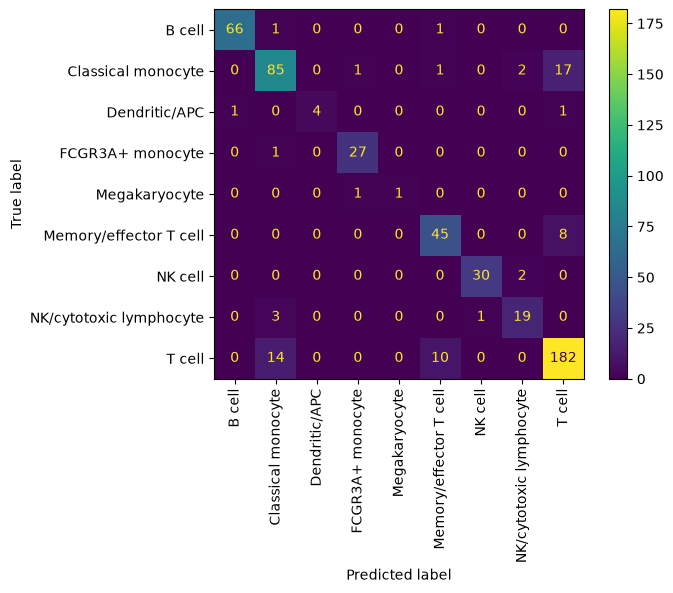

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=90)
plt.show()
# diagonal is the number of cells the model got correct
# off-diagonal shows what was misclassified

The model is confusing T/CD4 T cells with Naive T cells. This first model using 1987 gene features and 2092 cells is giving us 76% accuracy. What would it be if we used the 10 pca features instead? or if we did that with random forest or a pytorch neural network rather than logistic regression? 

Second model: using 50 pcs to do log reg, meaning instead of using 2000 genes to draw a line of best fit, we use the pcs that capture the most variance instead. 

In [43]:
# the pc coordinates are stored here. each row is a cell, and each col is a feature (pc)
# the location of each cell in each pc direction represents their type of gene expression
adata.obsm["X_pca"].shape


(2616, 50)

In [44]:
X_pca10 = adata.obsm["X_pca"][:, :10]
X_pca10.shape

(2616, 10)

In [45]:
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca10, 
    y, 
    test_size=0.2,
    random_state=42, 
    stratify=y
)

In [ ]:
model_pca10 = LogisticRegression(
    max_iter=1000
)
model_pca10.fit(X_train_pca, y_train_pca)

y_pred_pca10 = model_pca10.predict(X_test_pca)

accuracy_pca10 = accuracy_score(
    y_test_pca, y_pred_pca10
)
print(f"PCA 10 accuracy: {accuracy_pca10:.3f}")

PCA 10 accuracy: 0.927


Trying all 50 pcs now

In [ ]:
X_pca50 = adata.obsm["X_pca"]
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca50, 
    y, 
    test_size=0.2,
    random_state=42, 
    stratify=y
)

model_pca50 = LogisticRegression(
    max_iter=1000
)
model_pca50.fit(X_train_pca, y_train_pca)

y_pred_pca50 = model_pca50.predict(X_test_pca)

accuracy_pca50 = accuracy_score(
    y_test_pca, y_pred_pca50
)
print(f"PCA 50 accuracy: {accuracy_pca50:.3f}")
# the later pcs capture less variation and likely add noise

PCA 50 accuracy: 0.899


Fixing the data leakage 

In [53]:
# start with original X and y
X = adata.X
y = adata.obs["cell_type"]

# split data before doing pca
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# truncatedSVD is for sparse matrices that gives us pca-like dim reduction
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

# svd is a model/object that can store the 50pcs and estimate
# train svd with train data then translate into new coordinate system 
X_train_pca = svd.fit_transform(X_train)
X_test_pca = svd.transform(X_test)
# you end up with X test and train in new coordinate system

# just take first 10 pcs
X_train_10 = X_train_pca[:, :10]
X_test_10 = X_test_pca[:, :10]

# train log reg
model_10 = LogisticRegression(max_iter=5000)

model_10.fit(X_train_10, y_train)

y_pred_10 = model_10.predict(X_test_10)

# evaluate
accuracy_10 = accuracy_score(y_test, y_pred_10)

print(f"10-component accuracy: {accuracy_10:.3f}")
print(classification_report(y_test, y_pred_10))

10-component accuracy: 0.914
                         precision    recall  f1-score   support

                 B cell       1.00      0.99      0.99        68
     Classical monocyte       0.84      0.87      0.86       106
          Dendritic/APC       0.67      0.67      0.67         6
       FCGR3A+ monocyte       0.97      1.00      0.98        28
          Megakaryocyte       1.00      0.50      0.67         2
 Memory/effector T cell       0.90      0.87      0.88        53
                NK cell       0.97      0.97      0.97        32
NK/cytotoxic lymphocyte       0.87      0.87      0.87        23
                 T cell       0.92      0.92      0.92       206

               accuracy                           0.91       524
              macro avg       0.90      0.85      0.87       524
           weighted avg       0.91      0.91      0.91       524



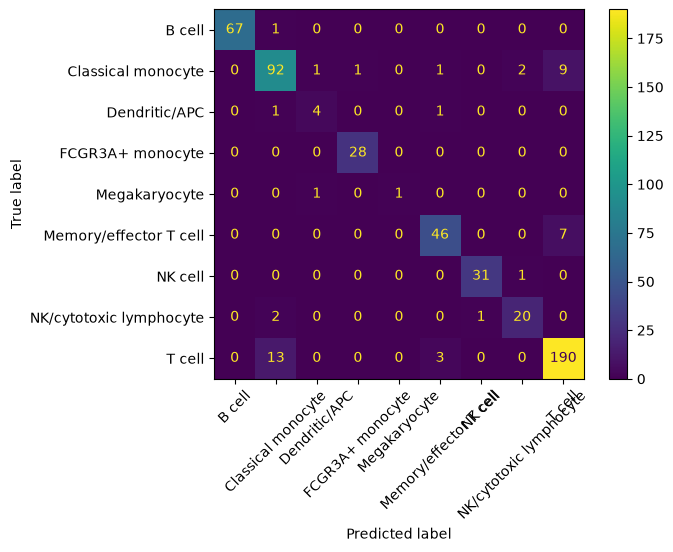

In [54]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_10,
    xticks_rotation=45
)